# **E-commerce Product Classification Using**

**Task 1: Import Required Libraries**

In [1]:
import os
import re
import html
import string
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    CountVectorizer
)

from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


**Task 2: Upload and Load Dataset**

In [2]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No file was uploaded.")

csv_candidates = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

if not csv_candidates:
    raise FileNotFoundError(
        "Please upload a CSV file."
    )

preferred_name = "ecommerceDataset.csv"

DATA_PATH = (
    preferred_name
    if preferred_name in csv_candidates
    else csv_candidates[0]
)

print("Selected file:", DATA_PATH)

Saving ecommerceDataset.csv to ecommerceDataset.csv
Selected file: ecommerceDataset.csv


In [3]:
df = pd.read_csv(
    DATA_PATH,
    header=None,
    usecols=[0, 1],
    names=["category", "description"],
    encoding="utf-8",
    on_bad_lines="warn"
)

# Remove header row if it exists unexpectedly
if (
    str(df.iloc[0]["category"]).strip().lower()
    in {"category", "label"}
    and
    str(df.iloc[0]["description"]).strip().lower()
    in {"description", "text"}
):
    df = df.iloc[1:].copy()

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (50425, 2)


,category,description
0,Household,Paper Plane Design Framed Wall Hanging Motivat...
1,Household,"SAF 'Floral' Framed Painting (Wood, 30 inch x ..."
2,Household,SAF 'UV Textured Modern Art Print Framed' Pain...
3,Household,"SAF Flower Print Framed Painting (Synthetic, 1..."
4,Household,Incredible Gifts India Wooden Happy Birthday U...


**Task 3: Explore Dataset Structure**

3.1 Dataset Information

In [4]:
print("Dataset Information:\n")

df.info()

print("\nDataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")

display(
    df.describe(include="all").T
)

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50425 entries, 0 to 50424
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   category     50425 non-null  object
 1   description  50424 non-null  object
dtypes: object(2)
memory usage: 788.0+ KB

Dataset Shape:
Rows: 50425
Columns: 2

Column Names:
['category', 'description']

Data Types:
category       object
description    object
dtype: object

Statistical Summary:


,count,unique,top,freq
category,50425,4,Household,19313
description,50424,27802,Think & Grow Rich About the Author NAPOLEON HI...,30


3.2 Display Random Samples

In [5]:
print("Random Samples from Dataset:")

display(
    df.sample(
        min(10, len(df)),
        random_state=RANDOM_STATE
    )
)

Random Samples from Dataset:


,category,description
35848,Clothing & Accessories,Kandy Men's Regular Fit Blazer Blue This produ...
13005,Household,HealthSense Chef-Mate KS 50 Digital Kitchen Sc...
22719,Books,Concept of Physics (2018-2019) Session (Set of...
18453,Household,Lista Stainless Steel Multi Functional Hammer ...
20867,Books,Gardening in Urban India update
8760,Household,ADTALA 20 LED Bright Outdoor ABS Security Ligh...
38004,Clothing & Accessories,KRISHNA FASHION Women's Cotton Traditional Pat...
34287,Clothing & Accessories,Lux Inferno Mens Cotton Thermal Bottom Lux Inf...
18524,Household,Stanley Combination Plier with 8 inch Single C...
32910,Clothing & Accessories,Biba Girls Anarkali Salwar Suit Set BIBA today...


3.3 Check Unique Categories

In [6]:
print("Unique Categories:")

print(
    df["category"]
    .value_counts(dropna=False)
)

print("\nNumber of Unique Categories:")

print(
    df["category"].nunique()
)

Unique Categories:
category
Household                 19313
Books                     11820
Electronics               10621
Clothing & Accessories     8671
Name: count, dtype: int64

Number of Unique Categories:
4


**Task 4: Data Quality Check and Cleaning**

4.1 Missing Values

In [7]:
print("Missing Values:")

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

display(missing_values)

Missing Values:


,Missing Count,Missing Percentage
category,0,0.0
description,1,0.0


4.2 Empty Values

In [8]:
empty_categories = (
    df["category"]
    .astype("string")
    .str.strip()
    .eq("")
)

empty_descriptions = (
    df["description"]
    .astype("string")
    .str.strip()
    .eq("")
)

print(
    "Empty Categories:",
    empty_categories.sum()
)

print(
    "Empty Descriptions:",
    empty_descriptions.sum()
)

Empty Categories: 0
Empty Descriptions: 0


4.3 Duplicate Values

In [9]:
print(
    "Duplicate Rows:",
    df.duplicated().sum()
)

print(
    "Duplicate Category-Description Pairs:",
    df.duplicated(
        subset=["category", "description"]
    ).sum()
)

Duplicate Rows: 22622
Duplicate Category-Description Pairs: 22622


4.4 Clean Dataset

In [10]:
# Remove missing values
df = df.dropna(
    subset=["category", "description"]
).copy()

# Convert columns to strings
df["category"] = (
    df["category"]
    .astype(str)
    .str.strip()
)

df["description"] = (
    df["description"]
    .astype(str)
    .str.strip()
)

# Remove empty values
df = df[
    (df["category"] != "") &
    (df["description"] != "")
].copy()

# Remove exact duplicates
before_deduplication = len(df)

df = df.drop_duplicates(
    subset=["category", "description"]
).reset_index(drop=True)

duplicates_removed = (
    before_deduplication - len(df)
)

print("Data Cleaning Completed!")

print(
    "Removed Duplicates:",
    duplicates_removed
)

print("Dataset Shape:", df.shape)

print(
    "Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Remaining Duplicates:",
    df.duplicated().sum()
)

Data Cleaning Completed!
Removed Duplicates: 22643
Dataset Shape: (27781, 2)
Missing Values: 0
Remaining Duplicates: 0


**Task 5: Exploratory Data Analysis (EDA)**

5.1 Class Distribution

In [11]:
class_counts = df["category"].value_counts()

class_percentages = (
    df["category"]
    .value_counts(normalize=True) * 100
)

class_summary = pd.DataFrame({
    "Number of Products": class_counts,
    "Percentage": class_percentages.round(2)
})

display(class_summary)

,Number of Products,Percentage
category,,
Household,10564,38.03
Books,6235,22.44
Clothing & Accessories,5674,20.42
Electronics,5308,19.11


5.2 Category Distribution Bar Chart

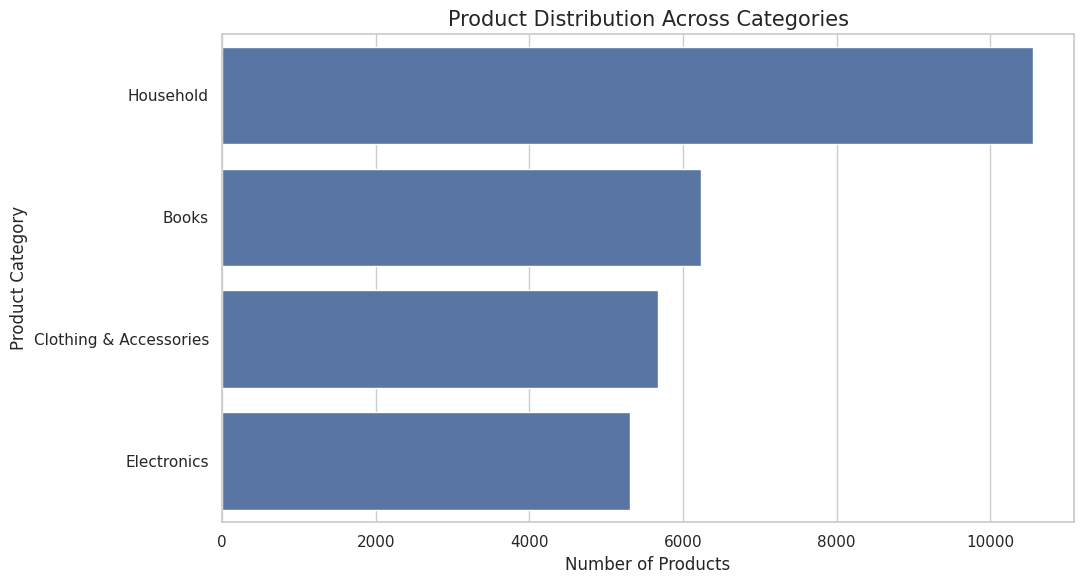

In [12]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    y="category",
    order=class_counts.index
)

plt.title(
    "Product Distribution Across Categories",
    fontsize=15
)

plt.xlabel("Number of Products")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

5.3 Category Distribution Pie Chart

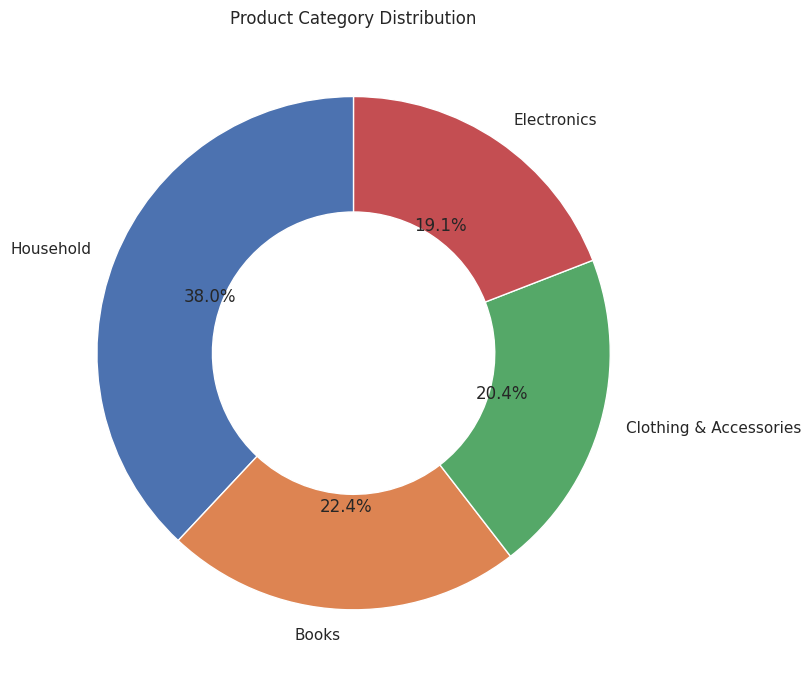

In [13]:
plt.figure(figsize=(9, 7))

plt.pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={
        "width": 0.45,
        "edgecolor": "white"
    }
)

plt.title(
    "Product Category Distribution"
)

plt.tight_layout()
plt.show()

5.4 Description Length Features

In [14]:
eda_df = df.copy()

eda_df["char_count"] = (
    eda_df["description"]
    .str.len()
)

eda_df["word_count"] = (
    eda_df["description"]
    .str.split()
    .str.len()
)

eda_df["avg_word_length"] = (
    eda_df["description"].apply(
        lambda text: np.mean([
            len(word)
            for word in str(text).split()
        ])
        if str(text).split()
        else 0
    )
)

eda_df["sentence_count"] = (
    eda_df["description"].apply(
        lambda text: max(
            1,
            len(re.findall(r"[.!?]+", str(text)))
        )
    )
)

display(
    eda_df[
        [
            "category",
            "char_count",
            "word_count",
            "avg_word_length",
            "sentence_count"
        ]
    ].head()
)

,category,char_count,word_count,avg_word_length,sentence_count
0,Household,1338,228,4.872807,14
1,Household,346,59,4.881356,2
2,Household,1316,224,4.392857,12
3,Household,1091,184,4.342391,10
4,Household,989,184,4.369565,10


5.5 Statistical Analysis by Category

In [15]:
statistics = (
    eda_df.groupby("category")[
        [
            "char_count",
            "word_count",
            "avg_word_length",
            "sentence_count"
        ]
    ]
    .agg([
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
    .round(2)
)

display(statistics)

char_count                            word_count  \
                             mean median      std min    max       mean   
category                                                                  
Books                      890.77  473.0  1824.22   4  50403     140.44   
Clothing & Accessories     446.90  344.5   384.92   4   3474      72.63   
Electronics                825.01  616.5   782.66   8  12473     130.46   
Household                  661.72  518.0   580.75   8  10168     107.01   

                                                avg_word_length               \
                       median     std min   max            mean median   std   
category                                                                       
Books                    74.0  298.09   1  8181            5.59   5.39  1.02   
Clothing & Accessories   56.0   62.84   1   581            5.26   5.11  0.94   
Electronics              97.0  123.79   1  1997            5.36   5.27  0.72   
Household                84.0   94.01   1  1791            5.23   5.14  0.64   

                                    sentence_count                         
                         min    max           mean median    std min  max  
category                                                                   
Books                   2.50  19.50           8.18    4.0  18.85   1  521  
Clothing & Accessories  3.00  32.78           4.35    3.0   4.56   1   80  
Electronics             3.19  19.76           8.02    5.0   9.00   1  225  
Household               2.80  18.00           6.24    4.0   6.35   1  103

5.6 Character Count Distribution

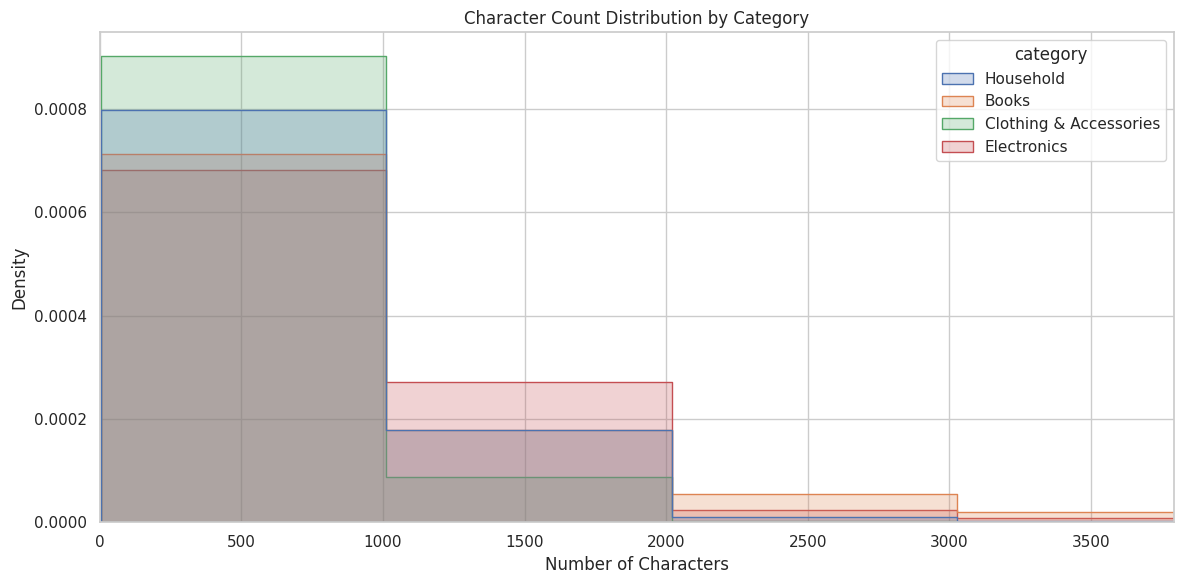

In [16]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=eda_df,
    x="char_count",
    hue="category",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(
    0,
    eda_df["char_count"].quantile(0.99)
)

plt.title(
    "Character Count Distribution by Category"
)

plt.xlabel("Number of Characters")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

5.7 Word Count Distribution

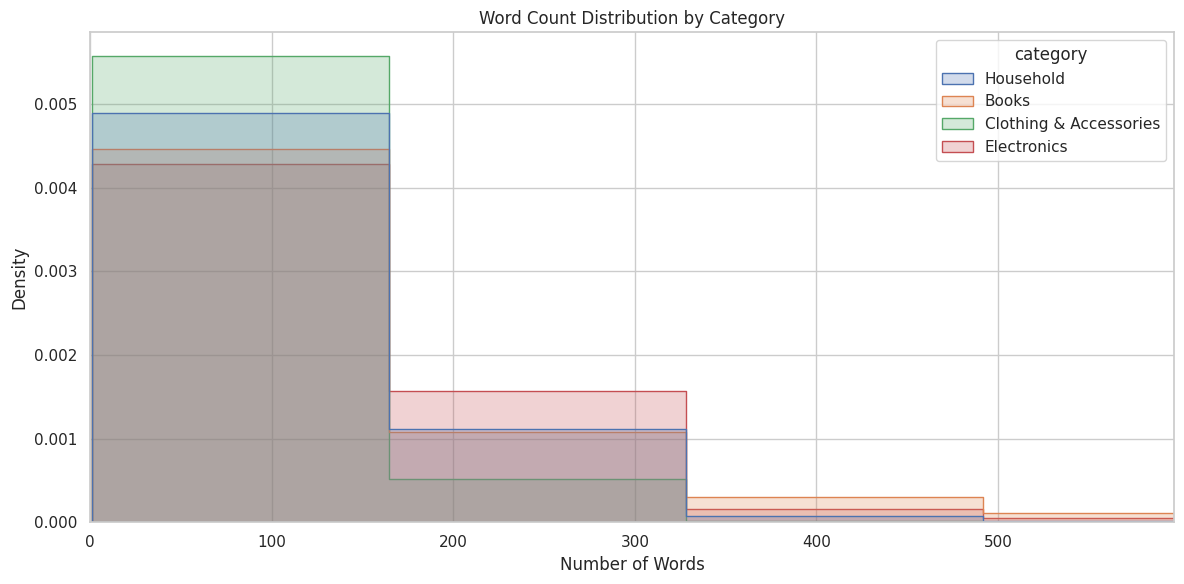

In [17]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=eda_df,
    x="word_count",
    hue="category",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(
    0,
    eda_df["word_count"].quantile(0.99)
)

plt.title(
    "Word Count Distribution by Category"
)

plt.xlabel("Number of Words")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

5.8 Boxplot: Word Count per Category

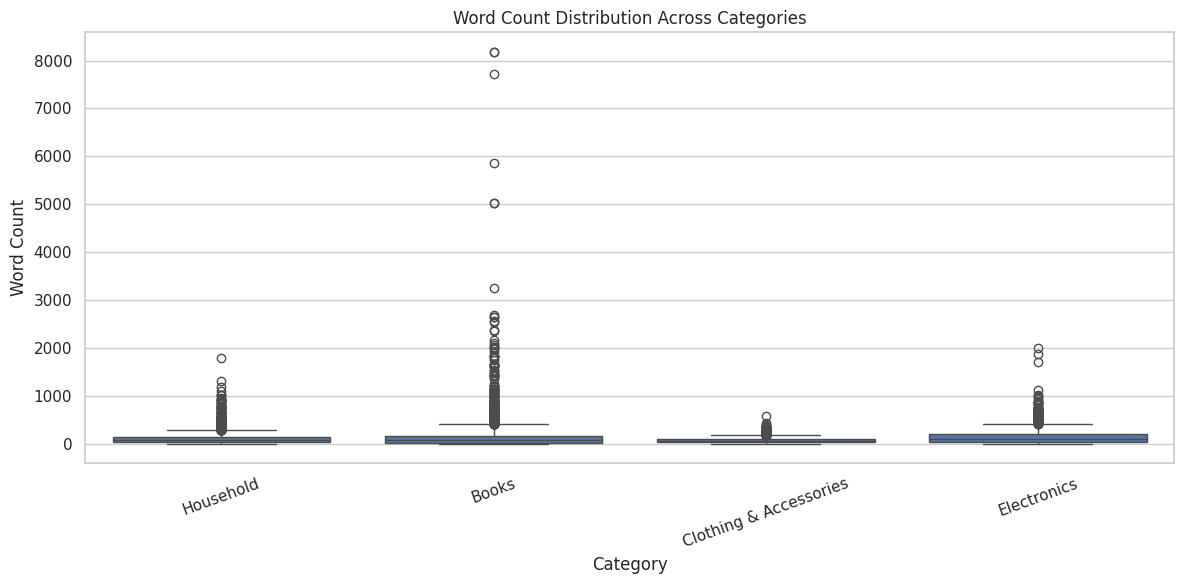

In [18]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=eda_df,
    x="category",
    y="word_count",
    order=class_counts.index
)

plt.title(
    "Word Count Distribution Across Categories"
)

plt.xlabel("Category")
plt.ylabel("Word Count")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

5.9 Boxplot: Character Count per Category

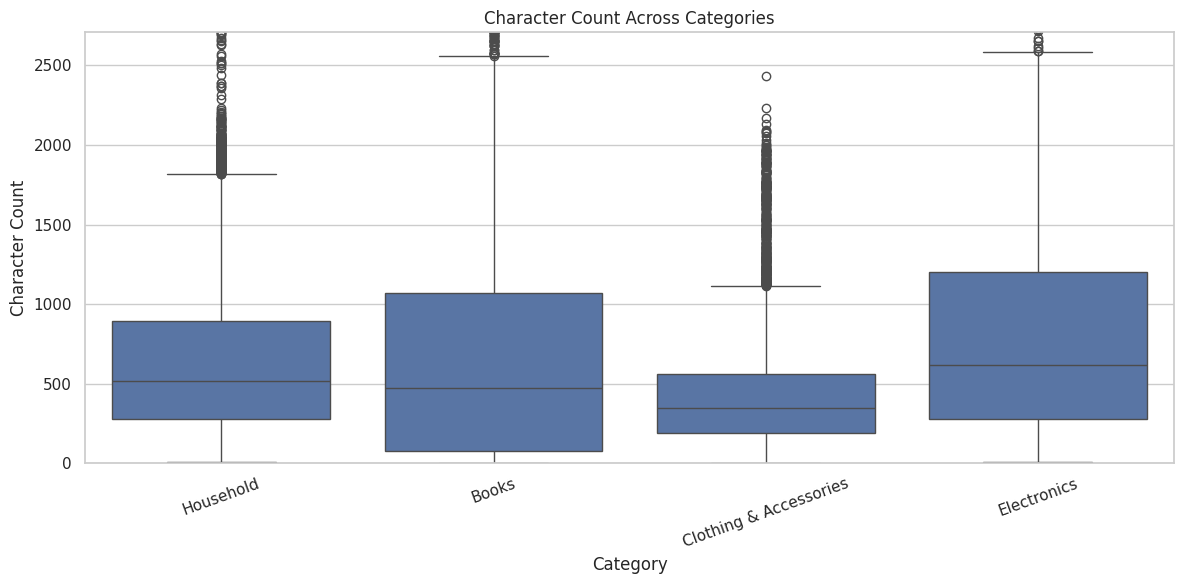

In [19]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=eda_df,
    x="category",
    y="char_count",
    order=class_counts.index
)

plt.ylim(
    0,
    eda_df["char_count"].quantile(0.98)
)

plt.title(
    "Character Count Across Categories"
)

plt.xlabel("Category")
plt.ylabel("Character Count")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

5.10 Average Word Length

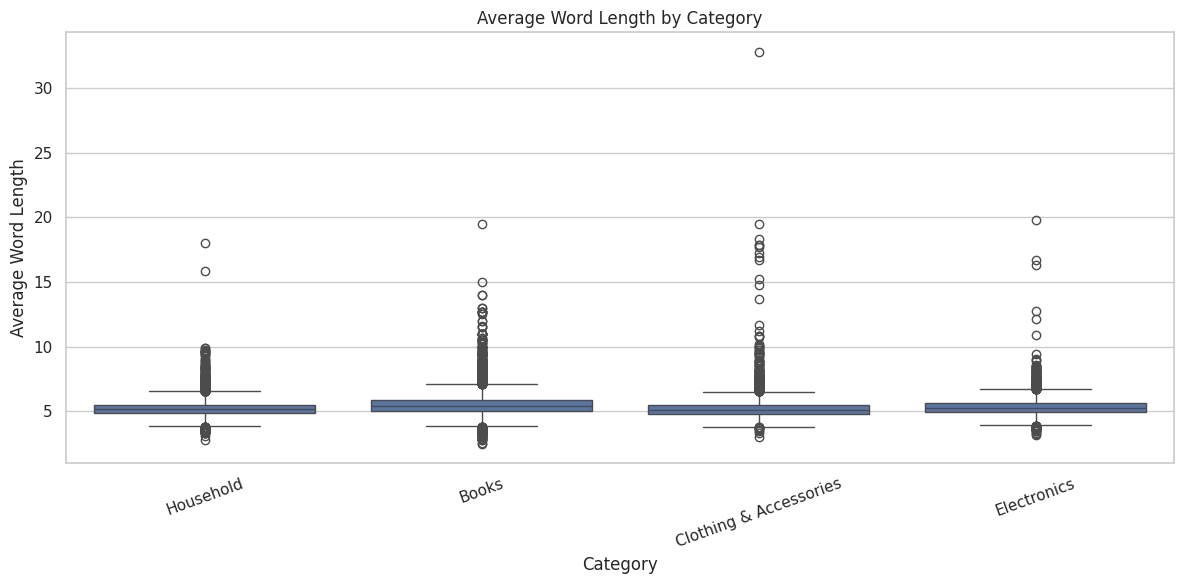

In [20]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=eda_df,
    x="category",
    y="avg_word_length",
    order=class_counts.index
)

plt.title(
    "Average Word Length by Category"
)

plt.xlabel("Category")
plt.ylabel("Average Word Length")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

5.11 Correlation Heatmap

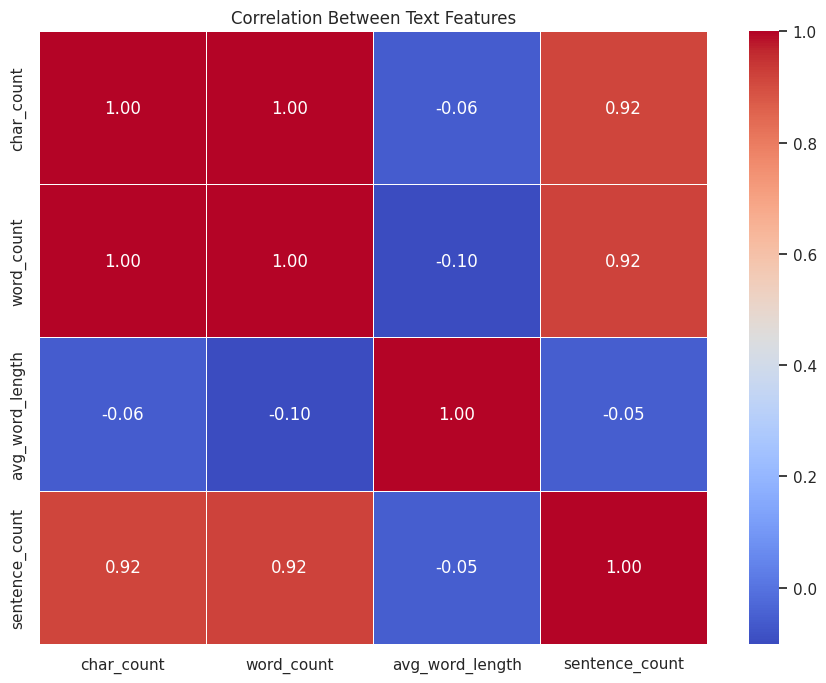

In [21]:
numeric_columns = [
    "char_count",
    "word_count",
    "avg_word_length",
    "sentence_count"
]

correlation = (
    eda_df[numeric_columns]
    .corr()
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Between Text Features"
)

plt.tight_layout()
plt.show()

5.12 Top Frequent Words per Category

In [22]:
basic_stopwords = {
    "the", "and", "for", "with", "this",
    "that", "from", "are", "was", "were",
    "you", "your", "has", "have", "had",
    "its", "our", "their", "will", "can",
    "all", "not", "but", "one", "use",
    "used", "new", "more", "than", "into",
    "also"
}


def get_top_words(text_series, n=15):

    tokens = []

    for text in text_series.astype(str):

        words = re.findall(
            r"[a-zA-Z]{2,}",
            text.lower()
        )

        tokens.extend([
            word
            for word in words
            if word not in basic_stopwords
        ])

    return Counter(tokens).most_common(n)

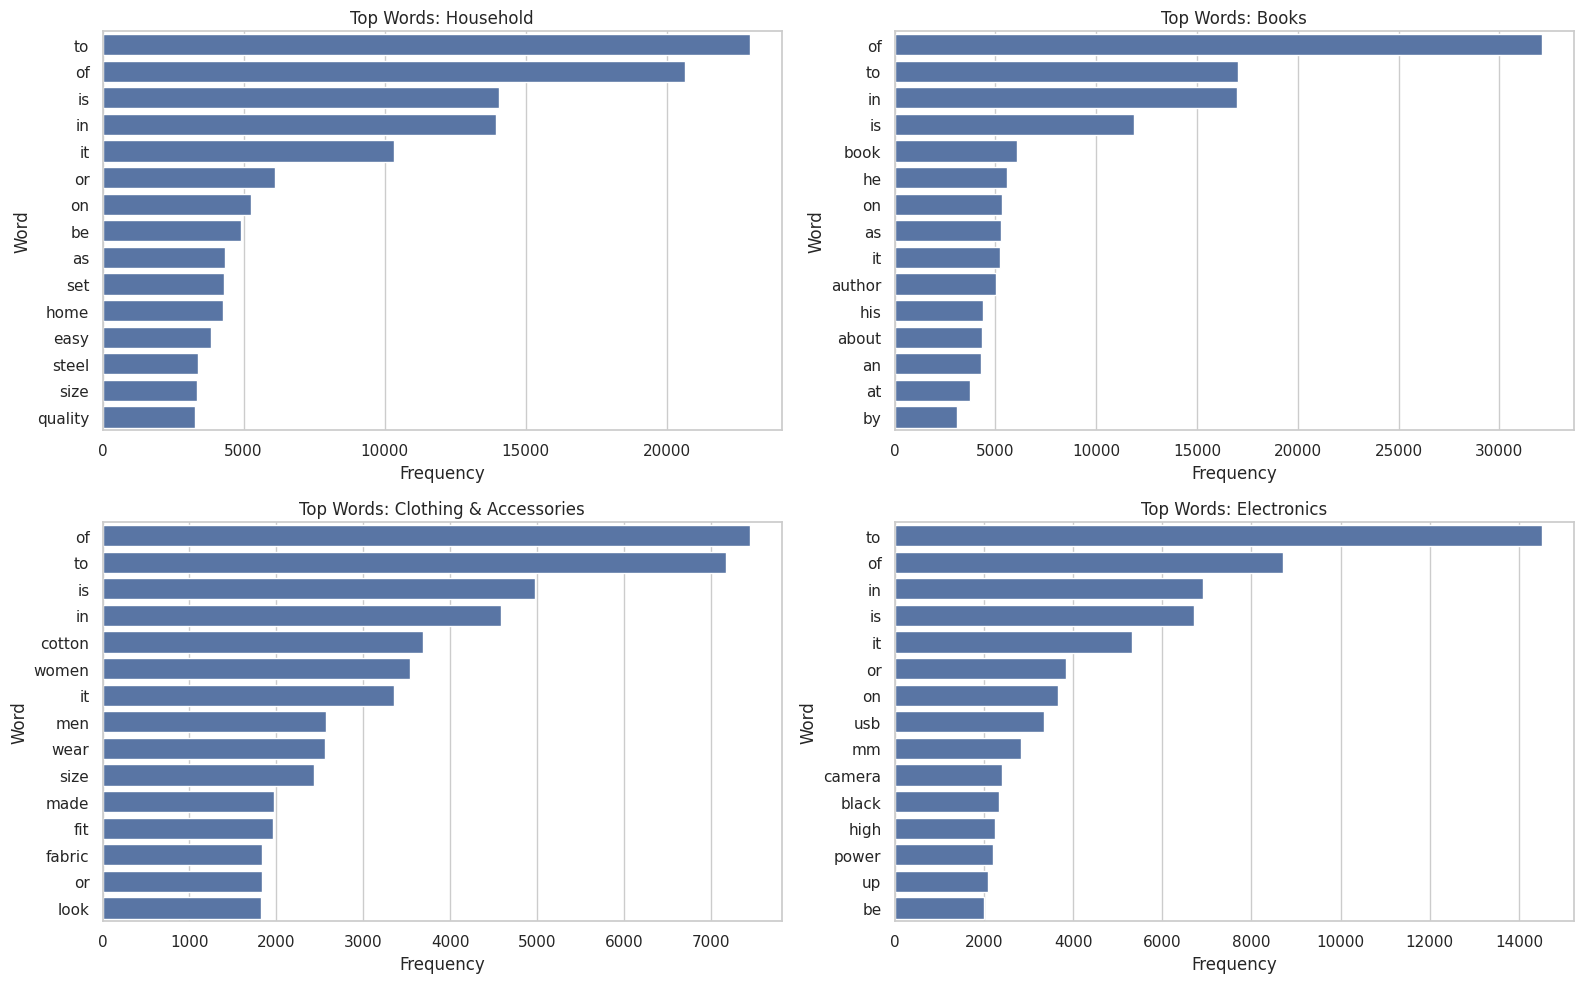

In [23]:
categories = list(class_counts.index)

n_cols = 2

n_rows = int(
    np.ceil(len(categories) / n_cols)
)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows)
)

axes = np.array(axes).reshape(-1)

for ax, category in zip(axes, categories):

    top_words = get_top_words(
        df.loc[
            df["category"] == category,
            "description"
        ],
        n=15
    )

    if top_words:

        words, counts = zip(*top_words)

        sns.barplot(
            x=list(counts),
            y=list(words),
            ax=ax
        )

    ax.set_title(
        f"Top Words: {category}"
    )

    ax.set_xlabel("Frequency")
    ax.set_ylabel("Word")

for ax in axes[len(categories):]:
    ax.remove()

plt.tight_layout()
plt.show()

5.13 Outlier Analysis

In [24]:
short_threshold = (
    eda_df["word_count"].quantile(0.01)
)

long_threshold = (
    eda_df["word_count"].quantile(0.99)
)

print(
    "1st Percentile:",
    short_threshold
)

print(
    "99th Percentile:",
    long_threshold
)

print("\nVery Short Descriptions:")

display(
    eda_df.nsmallest(
        10,
        "word_count"
    )[
        ["category", "description", "word_count"]
    ]
)

print("\nVery Long Descriptions:")

display(
    eda_df.nlargest(
        10,
        "word_count"
    )[
        ["category", "description", "word_count"]
    ]
)

1st Percentile: 4.0
99th Percentile: 597.0

Very Short Descriptions:


,category,description,word_count
10424,Household,Sourcery,1
10935,Books,Universe,1
11255,Books,Panorama,1
11558,Books,#Horror,1
11705,Books,Ramayana,1
11911,Books,Environment,1
12576,Books,Dracula,1
12628,Books,Essays,1
12731,Books,Siddhartha,1
13289,Books,Meditations,1



Very Long Descriptions:


,category,description,word_count
15333,Books,Risk Savvy: How to Make Good Decisions About t...,8181
15329,Books,Risk Savvy: How to Make Good Decisions About t...,8169
13387,Books,The Global War on Christians: Dispatches from ...,7724
12580,Books,Dracula (Enriched Classics) About the Author B...,5853
14466,Books,Mastering the Art of Selling Real Estate: Full...,5036
10909,Books,The Forty Rules of Love: A Novel of Rumi About...,5028
15322,Books,Defending Beef: The Case for Sustainable Meat ...,3258
16473,Books,"Lean In: Women, Work, and the Will to Lead Rev...",2685
11212,Books,How to Be a Bawse: A Guide to Conquering Life ...,2645
13147,Books,Life Without Limits: Inspiration for a Ridicul...,2644


**Task 6: Text Preprocessing**

6.1 Text Cleaning Function

In [25]:
def clean_text(text):

    text = str(text)

    # Decode HTML entities
    text = html.unescape(text)

    # Remove HTML tags
    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Remove email addresses
    text = re.sub(
        r"\b[\w.-]+@[\w.-]+\.\w+\b",
        " ",
        text
    )

    # Convert to lowercase
    text = text.lower()

    # Keep letters, numbers, and useful punctuation
    text = re.sub(
        r"[^a-z0-9\s&/+._'-]",
        " ",
        text
    )

    # Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

6.2 Apply Text Preprocessing

In [26]:
df["original_description"] = (
    df["description"]
)

df["clean_description"] = (
    df["description"].apply(clean_text)
)

# Remove empty descriptions
df = df[
    df["clean_description"].str.strip().ne("")
].reset_index(drop=True)

print("Text preprocessing completed!")

display(
    df[
        [
            "original_description",
            "clean_description",
            "category"
        ]
    ].head(10)
)

Text preprocessing completed!


,original_description,clean_description,category
0,Paper Plane Design Framed Wall Hanging Motivat...,paper plane design framed wall hanging motivat...,Household
1,"SAF 'Floral' Framed Painting (Wood, 30 inch x ...",saf 'floral' framed painting wood 30 inch x 10...,Household
2,SAF 'UV Textured Modern Art Print Framed' Pain...,saf 'uv textured modern art print framed' pain...,Household
3,"SAF Flower Print Framed Painting (Synthetic, 1...",saf flower print framed painting synthetic 13....,Household
4,Incredible Gifts India Wooden Happy Birthday U...,incredible gifts india wooden happy birthday u...,Household
5,Pitaara Box Romantic Venice Canvas Painting 6m...,pitaara box romantic venice canvas painting 6m...,Household
6,Paper Plane Design Starry Night Vangoh Wall Ar...,paper plane design starry night vangoh wall ar...,Household
7,SAF 'Ganesh Modern Art Print' Painting (Synthe...,saf 'ganesh modern art print' painting synthet...,Household
8,Paintings Villa UV Textured Modern Art Print F...,paintings villa uv textured modern art print f...,Household
9,Painting Mantra Art Street - Jardin Bird Frame...,painting mantra art street - jardin bird frame...,Household


6.3 Compare Original and Cleaned Text

In [27]:
sample_index = 0

print("Original Description:\n")

print(
    df.loc[
        sample_index,
        "original_description"
    ]
)

print("\nCleaned Description:\n")

print(
    df.loc[
        sample_index,
        "clean_description"
    ]
)

Original Description:

Paper Plane Design Framed Wall Hanging Motivational Office Decor Art Prints (8.7 X 8.7 inch) - Set of 4 Painting made up in synthetic frame with uv textured print which gives multi effects and attracts towards it. This is an special series of paintings which makes your wall very beautiful and gives a royal touch. This painting is ready to hang, you would be proud to possess this unique painting that is a niche apart. We use only the most modern and efficient printing technology on our prints, with only the and inks and precision epson, roland and hp printers. This innovative hd printing technique results in durable and spectacular looking prints of the highest that last a lifetime. We print solely with top-notch 100% inks, to achieve brilliant and true colours. Due to their high level of uv resistance, our prints retain their beautiful colours for many years. Add colour and style to your living space with this digitally printed painting. Some are for pleasure and

**Task 7: Define Features and Target**






In [28]:
X = df["clean_description"]

y = df["category"]

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nTarget Categories:")

print(sorted(y.unique()))

print(
    "\nNumber of Categories:",
    y.nunique()
)

Features Shape: (27781,)
Target Shape: (27781,)

Target Categories:
['Books', 'Clothing & Accessories', 'Electronics', 'Household']

Number of Categories: 4


**Task 8: Train-Test Split**

In [29]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=RANDOM_STATE,

    stratify=y
)

print(
    "Training Samples:",
    len(X_train)
)

print(
    "Testing Samples:",
    len(X_test)
)

print("\nTraining Distribution:")

print(
    y_train.value_counts()
)

print("\nTesting Distribution:")

print(
    y_test.value_counts()
)

Training Samples: 22224
Testing Samples: 5557

Training Distribution:
category
Household                 8451
Books                     4988
Clothing & Accessories    4539
Electronics               4246
Name: count, dtype: int64

Testing Distribution:
category
Household                 2113
Books                     1247
Clothing & Accessories    1135
Electronics               1062
Name: count, dtype: int64


Compare Class Distribution After Splitting

In [30]:
split_summary = pd.DataFrame({

    "Full Dataset (%)":
        y.value_counts(normalize=True) * 100,

    "Training Set (%)":
        y_train.value_counts(normalize=True) * 100,

    "Testing Set (%)":
        y_test.value_counts(normalize=True) * 100

}).fillna(0).round(2)

display(split_summary)

,Full Dataset (%),Training Set (%),Testing Set (%)
category,,,
Household,38.03,38.03,38.02
Books,22.44,22.44,22.44
Clothing & Accessories,20.42,20.42,20.42
Electronics,19.11,19.11,19.11


**Task 9: TF-IDF and Model Development**

9.1 Create TF-IDF Pipeline

In [31]:
def build_pipeline(classifier):

    return Pipeline([

        (
            "tfidf",

            TfidfVectorizer(

                lowercase=False,

                stop_words=None,

                ngram_range=(1, 2),

                min_df=2,

                max_df=0.98,

                max_features=100000,

                sublinear_tf=True,

                dtype=np.float32

            )
        ),

        (
            "classifier",

            classifier
        )

    ])

9.2 Define Classification Models

In [32]:
models = {

    "Multinomial Naive Bayes":

        MultinomialNB(
            alpha=1.0
        ),

    "Logistic Regression":

        LogisticRegression(
            C=1.0,
            max_iter=1500,
            random_state=RANDOM_STATE
        ),

    "Linear SVM":

        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=RANDOM_STATE
        )

}

print("Classification Models Defined Successfully!")

Classification Models Defined Successfully!


**Task 10: Cross Validation**

In [33]:
class_counts_train = y_train.value_counts()

n_splits = min(
    5,
    int(class_counts_train.min())
)

if n_splits < 2:

    raise ValueError(
        "At least 2 training samples per class "
        "are required for cross-validation."
    )

cv = StratifiedKFold(

    n_splits=n_splits,

    shuffle=True,

    random_state=RANDOM_STATE

)

scoring = {

    "accuracy": "accuracy",

    "precision_macro": "precision_macro",

    "recall_macro": "recall_macro",

    "f1_macro": "f1_macro",

    "f1_weighted": "f1_weighted"

}

Run Cross Validation

In [34]:
cv_results = []

for model_name, classifier in models.items():

    print(
        f"\nCross Validating: {model_name}"
    )

    pipeline = build_pipeline(classifier)

    scores = cross_validate(

        pipeline,

        X_train,

        y_train,

        cv=cv,

        scoring=scoring,

        n_jobs=-1,

        return_train_score=False

    )

    cv_results.append({

        "Model": model_name,

        "CV Accuracy Mean":
            scores["test_accuracy"].mean(),

        "CV Accuracy Std":
            scores["test_accuracy"].std(),

        "CV Macro Precision":
            scores["test_precision_macro"].mean(),

        "CV Macro Recall":
            scores["test_recall_macro"].mean(),

        "CV Macro F1":
            scores["test_f1_macro"].mean(),

        "CV Weighted F1":
            scores["test_f1_weighted"].mean()

    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(

    by="CV Macro F1",

    ascending=False

).reset_index(drop=True)

print("\nCross Validation Results:")

display(
    cv_results_df.style.format({

        col: "{:.4f}"

        for col in cv_results_df.columns

        if col != "Model"

    })
)


Cross Validating: Multinomial Naive Bayes

Cross Validating: Logistic Regression

Cross Validating: Linear SVM

Cross Validation Results:


,Model,CV Accuracy Mean,CV Accuracy Std,CV Macro Precision,CV Macro Recall,CV Macro F1,CV Weighted F1
0,Linear SVM,0.9565,0.0033,0.9583,0.9540,0.9561,0.9564
1,Logistic Regression,0.9471,0.0045,0.9520,0.9422,0.9467,0.9470
2,Multinomial Naive Bayes,0.9221,0.0062,0.9411,0.9095,0.9228,0.9221


Visualize Cross Validation Results

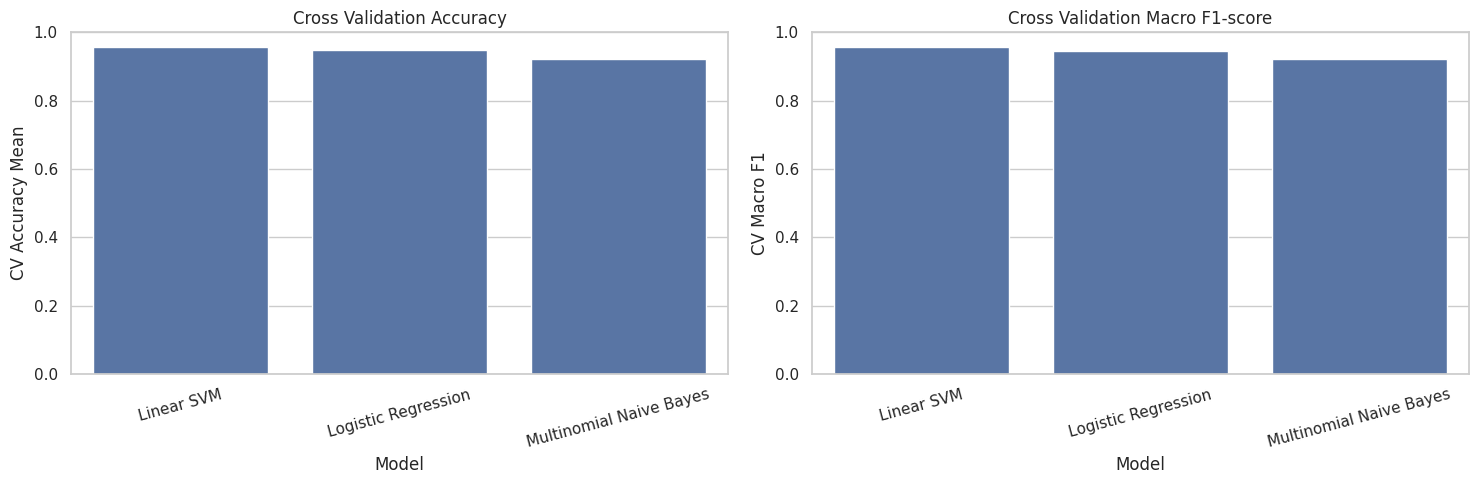

In [35]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

sns.barplot(

    data=cv_results_df,

    x="Model",

    y="CV Accuracy Mean",

    ax=axes[0]

)

axes[0].set_title(
    "Cross Validation Accuracy"
)

axes[0].set_ylim(0, 1)

axes[0].tick_params(
    axis="x",
    rotation=15
)

sns.barplot(

    data=cv_results_df,

    x="Model",

    y="CV Macro F1",

    ax=axes[1]

)

axes[1].set_title(
    "Cross Validation Macro F1-score"
)

axes[1].set_ylim(0, 1)

axes[1].tick_params(
    axis="x",
    rotation=15
)

plt.tight_layout()

plt.show()

**Task 11: Train Models**

In [36]:
trained_models = {}

test_predictions = {}

test_results = []

for model_name, classifier in models.items():

    print(
        f"\nTraining: {model_name}"
    )

    pipeline = build_pipeline(classifier)

    # Train model
    pipeline.fit(
        X_train,
        y_train
    )

    # Predict test data
    predictions = pipeline.predict(
        X_test
    )

    trained_models[model_name] = pipeline

    test_predictions[model_name] = predictions

    # Evaluation metrics
    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test,
        predictions,
        average="weighted",
        zero_division=0
    )

    test_results.append({

        "Model": model_name,

        "Test Accuracy": accuracy,

        "Test Macro Precision": precision,

        "Test Macro Recall": recall,

        "Test Macro F1": f1,

        "Test Weighted F1": weighted_f1

    })

    print(
        f"{model_name} trained successfully!"
    )

    print(
        f"Accuracy: {accuracy:.4f}"
    )

    print(
        f"Macro F1: {f1:.4f}"
    )

print("\nAll Models Trained Successfully!")


Training: Multinomial Naive Bayes
Multinomial Naive Bayes trained successfully!
Accuracy: 0.9302
Macro F1: 0.9313

Training: Logistic Regression
Logistic Regression trained successfully!
Accuracy: 0.9514
Macro F1: 0.9514

Training: Linear SVM
Linear SVM trained successfully!
Accuracy: 0.9611
Macro F1: 0.9610

All Models Trained Successfully!


**Task 12: Compare Models**

In [37]:
test_results_df = pd.DataFrame(
    test_results
)

comparison_df = cv_results_df.merge(
    test_results_df,
    on="Model"
)

print("Final Model Comparison:")

display(
    comparison_df.style.format({

        col: "{:.4f}"

        for col in comparison_df.columns

        if col != "Model"

    })
)

Final Model Comparison:


,Model,CV Accuracy Mean,CV Accuracy Std,CV Macro Precision,CV Macro Recall,CV Macro F1,CV Weighted F1,Test Accuracy,Test Macro Precision,Test Macro Recall,Test Macro F1,Test Weighted F1
0,Linear SVM,0.9565,0.0033,0.9583,0.9540,0.9561,0.9564,0.9611,0.9632,0.9590,0.9610,0.9611
1,Logistic Regression,0.9471,0.0045,0.9520,0.9422,0.9467,0.9470,0.9514,0.9556,0.9477,0.9514,0.9514
2,Multinomial Naive Bayes,0.9221,0.0062,0.9411,0.9095,0.9228,0.9221,0.9302,0.9452,0.9206,0.9313,0.9302


Accuracy Comparison

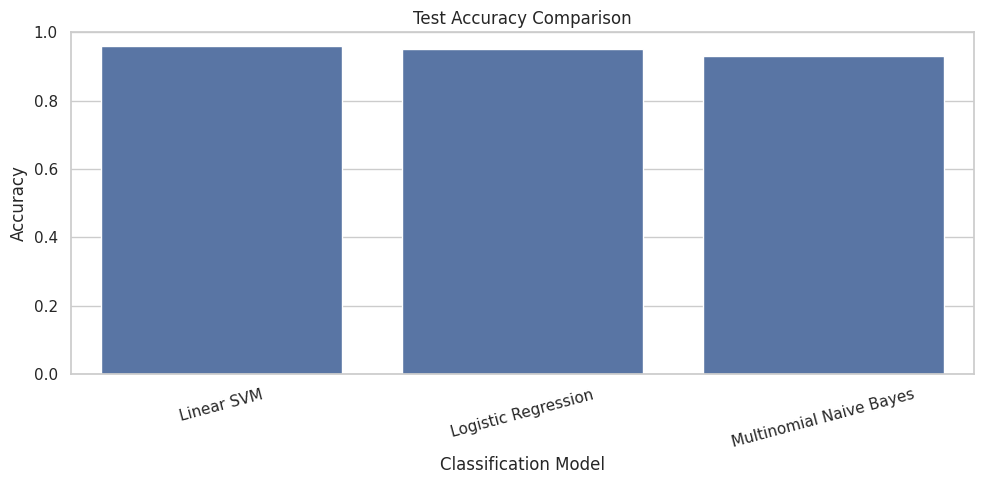

In [38]:
plt.figure(figsize=(10, 5))

sns.barplot(

    data=comparison_df,

    x="Model",

    y="Test Accuracy"

)

plt.title(
    "Test Accuracy Comparison"
)

plt.xlabel("Classification Model")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.tight_layout()

plt.show()

Macro F1 Comparison

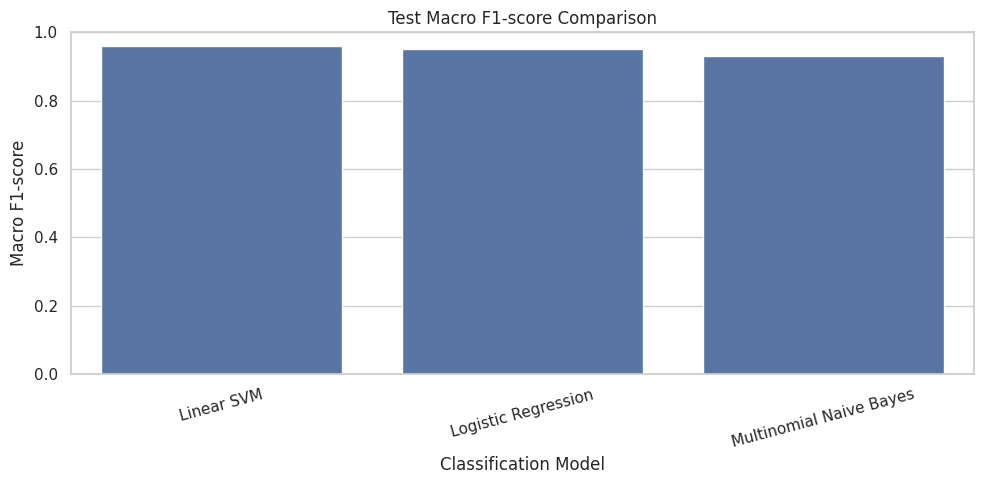

In [39]:
plt.figure(figsize=(10, 5))

sns.barplot(

    data=comparison_df,

    x="Model",

    y="Test Macro F1"

)

plt.title(
    "Test Macro F1-score Comparison"
)

plt.xlabel("Classification Model")

plt.ylabel("Macro F1-score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.tight_layout()

plt.show()

Compare All Evaluation Metrics

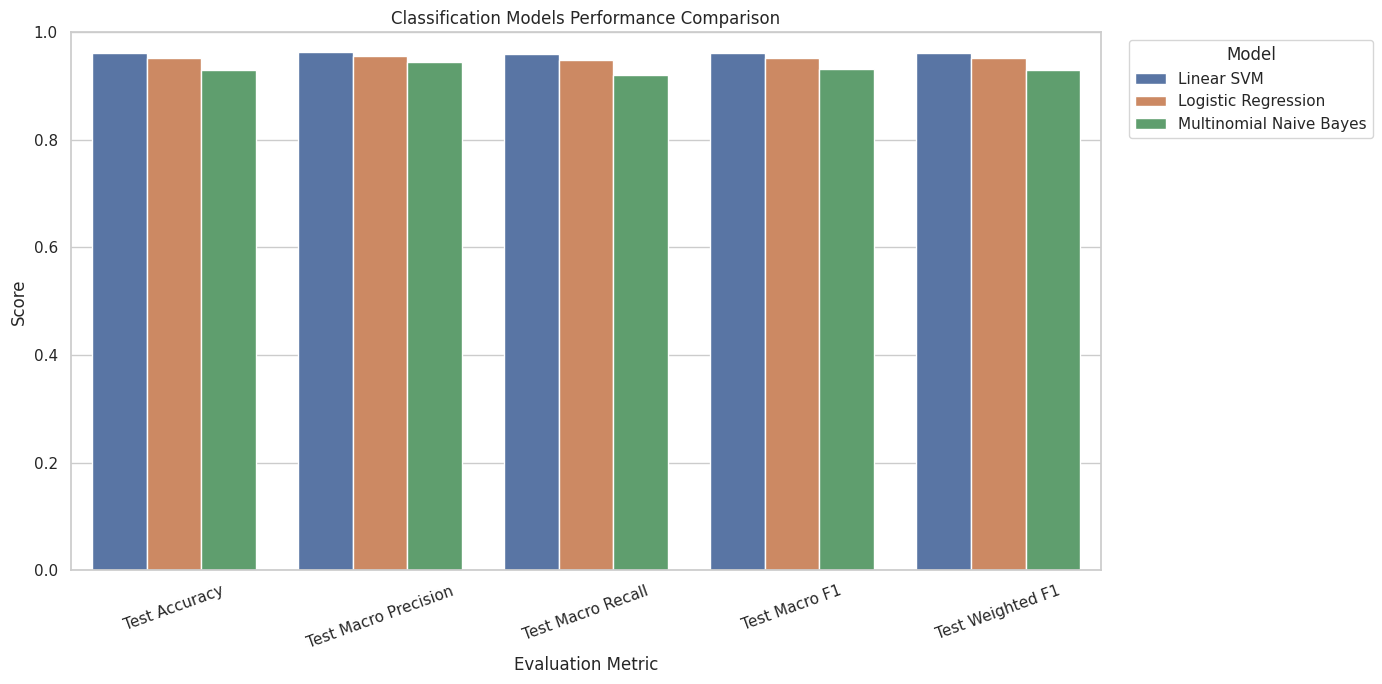

In [40]:
metrics_to_plot = [

    "Test Accuracy",

    "Test Macro Precision",

    "Test Macro Recall",

    "Test Macro F1",

    "Test Weighted F1"

]

comparison_long = comparison_df.melt(

    id_vars="Model",

    value_vars=metrics_to_plot,

    var_name="Metric",

    value_name="Score"

)

plt.figure(figsize=(14, 7))

sns.barplot(

    data=comparison_long,

    x="Metric",

    y="Score",

    hue="Model"

)

plt.title(
    "Classification Models Performance Comparison"
)

plt.ylabel("Score")

plt.xlabel("Evaluation Metric")

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

**Task 13: Select Best Model**

In [41]:
best_model_name = (
    cv_results_df.iloc[0]["Model"]
)

best_model = trained_models[
    best_model_name
]

y_pred_best = test_predictions[
    best_model_name
]

print(
    "Selected Best Model:",
    best_model_name
)

print(
    "Cross Validation Macro F1:",
    round(
        cv_results_df.iloc[0]["CV Macro F1"],
        4
    )
)

print(
    "Test Macro F1:",
    round(
        f1_score(
            y_test,
            y_pred_best,
            average="macro"
        ),
        4
    )
)

Selected Best Model: Linear SVM
Cross Validation Macro F1: 0.9561
Test Macro F1: 0.961


**Task 14: Detailed Model Evaluation**

In [42]:
print("Classification Report:\n")

print(
    classification_report(

        y_test,

        y_pred_best,

        labels=best_model.classes_,

        target_names=best_model.classes_,

        digits=4,

        zero_division=0

    )
)

Classification Report:

                        precision    recall  f1-score   support

                 Books     0.9647    0.9431    0.9538      1247
Clothing & Accessories     0.9832    0.9806    0.9819      1135
           Electronics     0.9542    0.9407    0.9474      1062
             Household     0.9509    0.9716    0.9611      2113

              accuracy                         0.9611      5557
             macro avg     0.9632    0.9590    0.9610      5557
          weighted avg     0.9612    0.9611    0.9611      5557



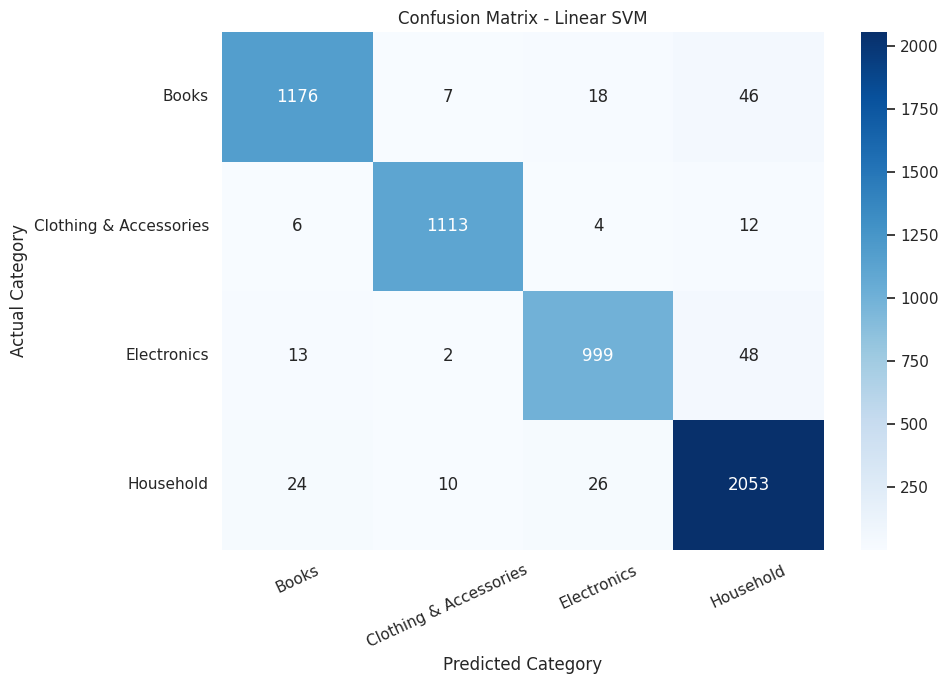

In [43]:
labels = list(
    best_model.classes_
)

cm = confusion_matrix(

    y_test,

    y_pred_best,

    labels=labels

)

plt.figure(figsize=(10, 7))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=labels,

    yticklabels=labels

)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel(
    "Predicted Category"
)

plt.ylabel(
    "Actual Category"
)

plt.xticks(rotation=25)

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

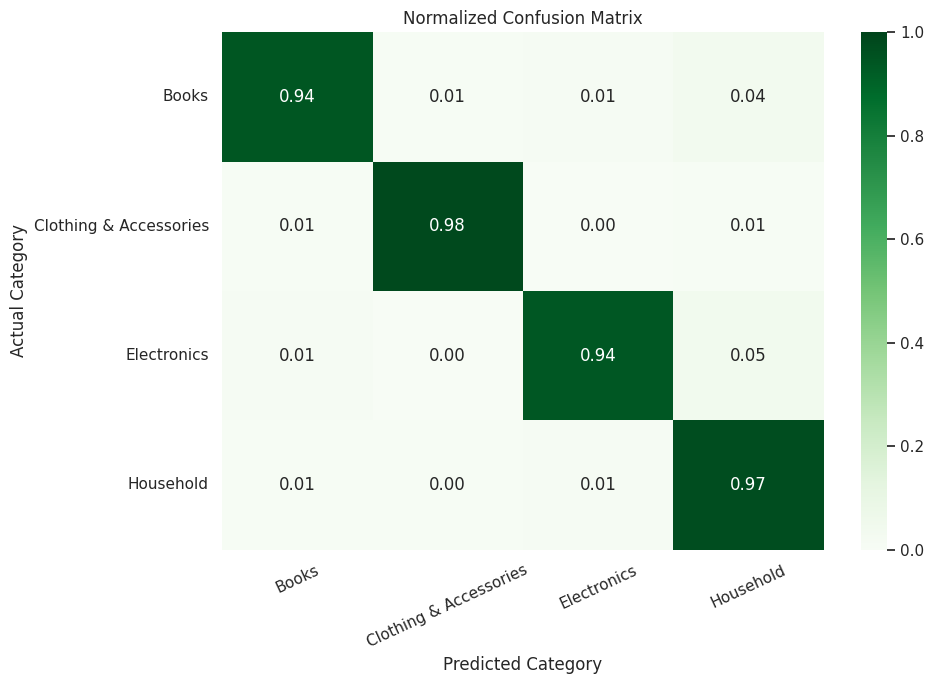

In [44]:
cm_normalized = confusion_matrix(

    y_test,

    y_pred_best,

    labels=labels,

    normalize="true"

)

plt.figure(figsize=(10, 7))

sns.heatmap(

    cm_normalized,

    annot=True,

    fmt=".2f",

    cmap="Greens",

    vmin=0,

    vmax=1,

    xticklabels=labels,

    yticklabels=labels

)

plt.title(
    "Normalized Confusion Matrix"
)

plt.xlabel(
    "Predicted Category"
)

plt.ylabel(
    "Actual Category"
)

plt.xticks(rotation=25)

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

**Task 15: Error Analysis**

In [45]:
error_analysis = pd.DataFrame({

    "description": X_test,

    "actual_category": y_test,

    "predicted_category": y_pred_best

})

misclassified = error_analysis[

    error_analysis["actual_category"]
    != error_analysis["predicted_category"]

].copy()

print(
    "Total Test Samples:",
    len(y_test)
)

print(
    "Misclassified Samples:",
    len(misclassified)
)

print(
    "Test Error Rate:",
    round(
        len(misclassified) / len(y_test),
        4
    )
)

display(
    misclassified.head(20)
)

Total Test Samples: 5557
Misclassified Samples: 216
Test Error Rate: 0.0389


,description,actual_category,predicted_category
693,intex inflatable baby float with sunshade cano...,Household,Books
25689,physicians formula super cc color-correction p...,Electronics,Household
11555,black+decker bmt154c professional hand tool ki...,Books,Household
23230,bbc 8803 gaming cabinet with one 3.0 usb and s...,Electronics,Household
13478,urvi creations pack of 20 natural peacock feat...,Books,Household
24753,sahibuy 3in1 5x zoom magnifying glass with led...,Electronics,Household
26245,five point someone about the author chetan bha...,Electronics,Books
9537,latches import jimi hendrix led a group called...,Household,Books
23873,brother hl-l2321d single-function monochrome l...,Electronics,Household
13402,gs museum silver plated royal pooja thali set ...,Books,Household


**Task 16: Predict New Product Categories**

In [46]:
def predict_product_category(
    description,
    model=best_model
):

    cleaned_description = clean_text(
        description
    )

    if not cleaned_description:

        raise ValueError(
            "Product description is empty after cleaning."
        )

    prediction = model.predict(
        [cleaned_description]
    )[0]

    return prediction

In [47]:
sample_products = [

    "Wireless Bluetooth headphones with noise cancellation",

    "Cotton printed t-shirt for men",

    "Python programming book for beginners",

    "Wooden wall shelf for home decoration",

    "Samsung 4K Smart LED television with Wi-Fi",

    "Stainless steel water bottle"

]

cleaned_products = [

    clean_text(product)

    for product in sample_products

]

predictions = best_model.predict(
    cleaned_products
)

prediction_df = pd.DataFrame({

    "Product Description":
        sample_products,

    "Cleaned Description":
        cleaned_products,

    "Predicted Category":
        predictions

})

display(prediction_df)

,Product Description,Cleaned Description,Predicted Category
0,Wireless Bluetooth headphones with noise cance...,wireless bluetooth headphones with noise cance...,Electronics
1,Cotton printed t-shirt for men,cotton printed t-shirt for men,Clothing & Accessories
2,Python programming book for beginners,python programming book for beginners,Books
3,Wooden wall shelf for home decoration,wooden wall shelf for home decoration,Household
4,Samsung 4K Smart LED television with Wi-Fi,samsung 4k smart led television with wi-fi,Electronics
5,Stainless steel water bottle,stainless steel water bottle,Household


**17. Save results**

In [48]:
MODEL_PATH = (
    "best_ecommerce_classifier.joblib"
)

joblib.dump(
    best_model,
    MODEL_PATH
)

print(
    "Model saved successfully!"
)

Model saved successfully!


In [49]:
comparison_df.to_csv(

    "model_comparison_results.csv",

    index=False

)

cv_results_df.to_csv(

    "cross_validation_results.csv",

    index=False

)

misclassified.to_csv(

    "misclassified_examples.csv",

    index=False

)

print(
    "Results saved successfully!"
)

Results saved successfully!


In [50]:
metadata = {

    "selected_model":
        best_model_name,

    "categories":
        [
            str(category)
            for category in best_model.classes_
        ],

    "random_state":
        RANDOM_STATE,

    "selection_metric":
        "Mean Cross-Validation Macro F1",

    "text_preprocessing":
        "clean_text() function in notebook",

    "tfidf_parameters":
        best_model.named_steps[
            "tfidf"
        ].get_params()

}

joblib.dump(
    metadata,
    "model_metadata.joblib"
)

print(
    "Model metadata saved successfully!"
)

Model metadata saved successfully!


In [51]:
from google.colab import files

files.download(
    "best_ecommerce_classifier.joblib"
)

files.download(
    "model_comparison_results.csv"
)

files.download(
    "cross_validation_results.csv"
)

files.download(
    "misclassified_examples.csv"
)

files.download(
    "model_metadata.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
print("=" * 65)

print(
    "E-COMMERCE PRODUCT CLASSIFICATION USING NLP"
)

print("=" * 65)

print(
    "\nDataset Rows:",
    len(df)
)

print(
    "Number of Categories:",
    df["category"].nunique()
)

print(
    "Training Samples:",
    len(X_train)
)

print(
    "Testing Samples:",
    len(X_test)
)

print("\nCross Validation Results:")

display(
    cv_results_df.round(4)
)

print(
    "\nSelected Best Model:",
    best_model_name
)

print(
    "\nTest Accuracy:",
    round(
        accuracy_score(
            y_test,
            y_pred_best
        ),
        4
    )
)

print(
    "Test Macro Precision:",
    round(
        precision_score(
            y_test,
            y_pred_best,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    "Test Macro Recall:",
    round(
        recall_score(
            y_test,
            y_pred_best,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    "Test Macro F1-score:",
    round(
        f1_score(
            y_test,
            y_pred_best,
            average="macro",
            zero_division=0
        ),
        4
    )
)

print(
    "\nMisclassified Samples:",
    len(misclassified)
)

print("\nProject Completed Successfully!")

print("=" * 65)

E-COMMERCE PRODUCT CLASSIFICATION USING NLP

Dataset Rows: 27781
Number of Categories: 4
Training Samples: 22224
Testing Samples: 5557

Cross Validation Results:


,Model,CV Accuracy Mean,CV Accuracy Std,CV Macro Precision,CV Macro Recall,CV Macro F1,CV Weighted F1
0,Linear SVM,0.9565,0.0033,0.9583,0.9540,0.9561,0.9564
1,Logistic Regression,0.9471,0.0045,0.9520,0.9422,0.9467,0.9470
2,Multinomial Naive Bayes,0.9221,0.0062,0.9411,0.9095,0.9228,0.9221



Selected Best Model: Linear SVM

Test Accuracy: 0.9611
Test Macro Precision: 0.9632
Test Macro Recall: 0.959
Test Macro F1-score: 0.961

Misclassified Samples: 216

Project Completed Successfully!
